# Densité mammaire en régression ordinale — MIAS
### Cross-entropy (nominal) vs CORN (ordinal) · Quadratic Weighted Kappa

---
## Résultat obtenu — validation croisée 5 plis × 3 seeds, 322 images

| | QWK moyen | écart-type inter-pli |
|---|---|---|
| Cross-entropy (nominal) | 0,7875 | 0,061 |
| CORN (ordinal) | **0,7923** | 0,060 |

**Delta apparié : +0,005, IC 95 % [−0,024 ; +0,034]** (n = 5 plis, loi de Student,
t = 0,46). CORN gagne sur 8 comparaisons sur 15 ; test des signes p = 1,00.

**Conclusion : aucune différence significative entre les deux approches sur MIAS.**
Ni confirmation ni réfutation de l'hypothèse ordinale. Les deux modèles atteignent
un QWK d'environ 0,79, ce qui est correct pour une densité à 3 niveaux sur des
mammographies numérisées à partir de films.

Le protocole initial — un seul découpage, 80 images de test — donnait un delta
apparent de **−0,049**, soit CORN nettement moins bon. C'était un artefact :
intervalle de confiance deux fois plus large, et sélection du checkpoint sur le
maximum d'un QWK de validation calculé sur 48 images. La validation croisée l'a
corrigé. Voir la section 10.

---
Version MIAS du projet, utilisée parce que VinDr-Mammo n'est pas téléchargeable en
pratique : PhysioNet plafonne à ~86 Ko/s pour des DICOM de 19,7 Mo, soit ~76 h pour
un sous-ensemble utilisable.

**Le nombre de classes ordinales diffère de la version VinDr-Mammo.** Le miroir
Kaggle fournit deux colonnes de densité. `BG` est l'annotation MIAS originale,
ordinale à 3 niveaux (F < G < D). `DENSITY` (A/B/C/D) est *dérivée* de `BG` par
correspondance un-pour-un, avec la catégorie A entièrement vide : ce n'est pas une
annotation de radiologue, et MIAS ne contient aucun BI-RADS de densité. C'est donc
`BG` qui est utilisé ici.

| | MIAS | VinDr-Mammo |
|---|---|---|
| Densité | F < G < D (3 niveaux, annotation originale) | BI-RADS A < B < C < D (4 niveaux) |
| Images | 322 | 20 000 |
| Technologie | film numérisé | numérique plein champ (FFDM) |
| Licence | CC BY 2.0 UK | DUA PhysioNet restrictive |

Même backbone, même protocole, même métrique que la version VinDr-Mammo. La tête
CORN produit K−1 logits, quel que soit K.

## 1. Environnement et données

In [1]:
!nvidia-smi -L
import torch, sys
print("torch", torch.__version__, "| CUDA:", torch.cuda.is_available())

GPU 0: Tesla T4 (UUID: GPU-614ca615-1ab1-503e-9043-e611da3ebf99)
GPU 1: Tesla T4 (UUID: GPU-168000aa-3f1b-9ec2-4748-d368baa17c5c)
torch 2.10.0+cu128 | CUDA: True


Deux façons d'amener les données. Sur Colab, dépose l'archive du cache dans ton
Drive puis décompresse-la. Sur Kaggle, ajoute le dataset MIAS comme source de
données et lance `prepare_mias.py` directement dans la session.

In [2]:
import os, re, glob, json, numpy as np, pandas as pd
from PIL import Image

SRC      = None            # None = detection auto sous /kaggle/input
OUT      = "/kaggle/working/mias_cache"   # /kaggle/input est en LECTURE SEULE
IMG_SIZE = 512
TEST_FRAC, SEED = 0.25, 42

BG = {"F": 0, "G": 1, "D": 2}
CLASS_NAMES, N_CLASSES = ["F", "G", "D"], 3
IMG_EXT = (".pgm", ".png", ".jpg", ".jpeg", ".tif", ".tiff")

def norm_id(v):
    m = re.search(r"mdb(\d{1,4})", str(v), re.I)
    return f"mdb{int(m.group(1)):03d}" if m else None

roots = [SRC] if SRC else sorted(glob.glob("/kaggle/input/*"))
images, csvs = {}, []
for root in roots:
    for p in glob.glob(os.path.join(root, "**", "*"), recursive=True):
        low = p.lower()
        if low.endswith(".csv"):
            csvs.append(p)
        elif low.endswith(IMG_EXT):
            k = norm_id(os.path.basename(p))
            if k is None: continue
            prio = (1 if low.endswith(".pgm") else 0, os.path.getsize(p))
            if k not in images or prio > images[k][0]:
                images[k] = (prio, p)
images = {k: v[1] for k, v in images.items()}
print(f"[scan] {len(images)} images | {len(csvs)} fichiers CSV")
assert images, "Aucune image trouvee sous /kaggle/input."

csvs.sort(key=lambda p: 1 if "derived" in os.path.basename(p).lower() else 0)
labels_map, used_csv, used_cols = {}, None, None
for c in csvs:
    df = pd.read_csv(c, dtype=str)
    cols = {re.sub(r"\s+", " ", str(x)).strip().upper(): x for x in df.columns}
    idc = next((cols[n] for n in ("MIAS NO","MIAS_NO","REFNUM","ID") if n in cols), None)
    bgc = next((cols[n] for n in ("BG","BACKGROUND","BACKGROUND_TISSUE","TISSUE") if n in cols), None)
    if not (idc and bgc): continue
    for i, b in zip(df[idc], df[bgc]):
        k, d = norm_id(i), BG.get(str(b).strip().upper())
        if k and d is not None: labels_map[k] = d
    if labels_map:
        used_csv, used_cols = os.path.basename(c), (idc, bgc); break
assert labels_map, f"Colonnes 'MIAS No' + 'BG' introuvables dans {[os.path.basename(x) for x in csvs]}"
print(f"[labels] {used_csv} : '{used_cols[0]}' + '{used_cols[1]}' -> {len(labels_map)} images")

communs = sorted(set(labels_map) & set(images))
print(f"[match] {len(communs)} images etiquetees ET presentes")
assert communs, "Aucune correspondance CSV / fichiers image."

pat = lambda k: f"p{(int(k[3:]) + 1) // 2:03d}"
pat_dens = {}
for k in communs:
    pat_dens[pat(k)] = max(pat_dens.get(pat(k), -1), labels_map[k])

rng, assign = np.random.default_rng(SEED), {}
for d in range(N_CLASSES):
    grp = sorted([p for p, v in pat_dens.items() if v == d]); rng.shuffle(grp)
    n_te = max(1, round(len(grp) * TEST_FRAC))
    assign.update({p: "test" for p in grp[:n_te]})
    assign.update({p: "training" for p in grp[n_te:]})

CACHE_DIR = os.path.join(OUT, "cache")
os.makedirs(CACHE_DIR, exist_ok=True)
rows = []
for n, k in enumerate(communs, 1):
    out_npy = os.path.join(CACHE_DIR, f"{k}.npy")
    if not os.path.exists(out_npy):
        im = Image.open(images[k]).convert("L")
        a = np.asarray(im, dtype=np.float32)
        a = (a - a.min()) / max(float(a.max() - a.min()), 1e-6)
        im = Image.fromarray((a * 255).astype(np.uint8))
        w, h = im.size; s = IMG_SIZE / max(w, h)
        im = im.resize((max(1, round(w*s)), max(1, round(h*s))), Image.BILINEAR)
        cv = Image.new("L", (IMG_SIZE, IMG_SIZE), 0)
        cv.paste(im, ((IMG_SIZE-im.size[0])//2, (IMG_SIZE-im.size[1])//2))
        with open(out_npy, "wb") as fh:
            np.save(fh, np.asarray(cv, dtype=np.uint8))
    rows.append({"image_id": k, "patient_id": pat(k),
                 "density_label": labels_map[k], "split": assign[pat(k)]})
    if n % 100 == 0: print(f"  converti {n}/{len(communs)}")

labels = pd.DataFrame(rows)
labels.to_csv(os.path.join(OUT, "labels.csv"), index=False)

print(f"\n{len(labels)} images | {labels['patient_id'].nunique()} patientes")
print(f"echelle : BG -> {N_CLASSES} classes {CLASS_NAMES}")
print("\nDistribution (lignes = split, colonnes = densite) :")
print(labels.groupby(["split", "density_label"]).size().unstack(fill_value=0).to_string())

assert labels["density_label"].between(0, N_CLASSES-1).all()
for split_name, g in labels.groupby("split"):
    vides = [k for k in range(N_CLASSES) if k not in set(g["density_label"])]
    if vides: print(f"\n[ATTENTION] {split_name} : classes {vides} absentes")
    faibles = {int(k): int(v) for k, v in g['density_label'].value_counts().items() if v < 15}
    if faibles: print(f"[warn] {split_name}: classes sous 15 images {faibles}")

mb = sum(e.stat().st_size for e in os.scandir(CACHE_DIR)) / 1e6
print(f"\ncache : {len(os.listdir(CACHE_DIR))} fichiers .npy, {mb:.0f} Mo -> {CACHE_DIR}")

[scan] 322 images | 2 fichiers CSV
[labels] mias_info.csv : 'REFNUM' + 'BG' -> 322 images
[match] 322 images etiquetees ET presentes
  converti 100/322
  converti 200/322
  converti 300/322

322 images | 161 patientes
echelle : BG -> 3 classes ['F', 'G', 'D']

Distribution (lignes = split, colonnes = densite) :
density_label   0   1   2
split                    
test           26  26  28
training       80  78  84

cache : 322 fichiers .npy, 84 Mo -> /kaggle/working/mias_cache/cache


## 2. Contrôle visuel

À ne pas sauter : les images doivent aller du sein clair et peu texturé (F,
adipeux) au sein dense et opaque (D). Si l'ordre paraît inversé, la variable
ordinale est mal orientée et tout le reste serait faux.

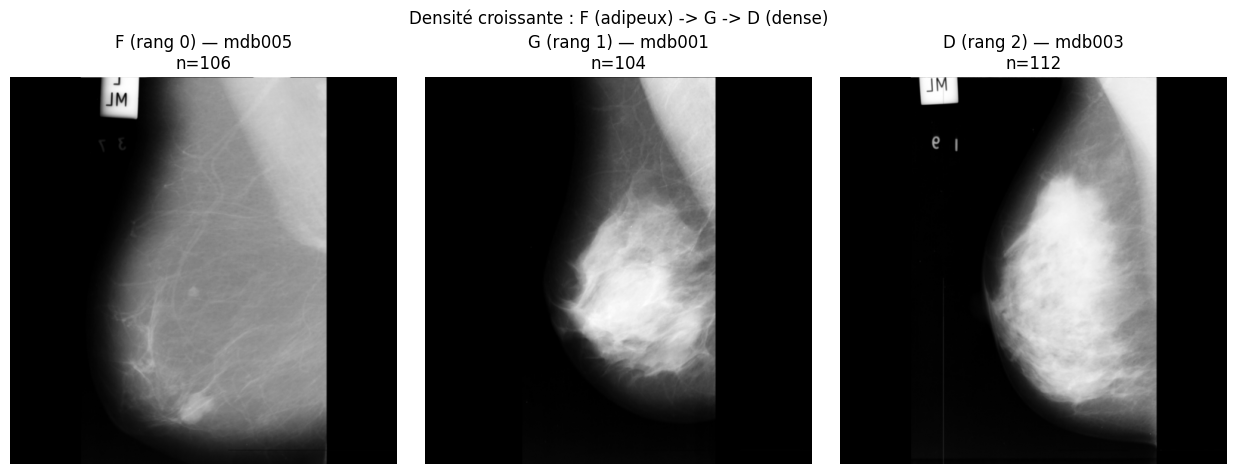

luminosité moyenne par classe : [59.9, 54.9, 44.9]
croissante : False


In [3]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, N_CLASSES, figsize=(4.2*N_CLASSES, 4.6))
for k, ax in enumerate(np.atleast_1d(axes)):
    sub = labels[labels["density_label"] == k]
    if len(sub) == 0:
        ax.axis("off"); continue
    r = sub.iloc[0]
    arr = np.load(os.path.join(CACHE_DIR, f"{r['image_id']}.npy"))
    ax.imshow(arr, cmap="gray"); ax.axis("off")
    ax.set_title(f"{CLASS_NAMES[k]} (rang {k}) — {r['image_id']}\nn={len(sub)}")
plt.suptitle("Densité croissante : F (adipeux) -> G -> D (dense)", y=1.02)
plt.tight_layout(); plt.show()

# Vérification quantitative : la luminosité moyenne doit croître avec la densité
moy = []
for k in range(N_CLASSES):
    ids = labels[labels["density_label"] == k]["image_id"].head(30)
    v = [np.load(os.path.join(CACHE_DIR, f"{i}.npy")).mean() for i in ids]
    moy.append(np.mean(v) if v else np.nan)
print("luminosité moyenne par classe :", [round(float(m), 1) for m in moy])
print("croissante :", all(moy[i] < moy[i+1] for i in range(N_CLASSES-1)))

**Le contrôle ci-dessus a échoué, et c'est mon test qui était mal conçu.**

Il affiche `[59,9 ; 54,9 ; 44,9] croissante : False` — la luminosité moyenne
*décroît* avec la densité, alors qu'on attend l'inverse, le tissu fibro-glandulaire
atténuant davantage les rayons X.

Ce n'est pas une inversion des images. C'est un biais de mesure : la moyenne porte
sur toute l'image, fond noir du letterbox inclus. Les seins denses appartiennent à
des femmes plus jeunes, donc plus petits, donc laissent plus de fond noir dans le
cadre, ce qui abaisse la moyenne. La cellule suivante refait la mesure **à
l'intérieur du sein uniquement**.

In [ ]:
# Controle corrige : luminosite mesuree DANS LE SEIN, et non sur toute l'image.
# Le fond noir biaisait la moyenne, la taille du sein etant correlee a la densite.
def stats_sein(arr, seuil=25):
    m = arr > seuil                      # masque grossier du tissu
    if m.sum() < 100:
        return np.nan, np.nan, np.nan
    v = arr[m].astype(np.float32)
    return v.mean(), v.std(), m.mean()   # luminosite, texture, surface relative

print(f"{'classe':>8} {'n':>4} {'luminosite':>11} {'texture':>9} {'surface':>8}")
lum, tex, sur = [], [], []
for k in range(N_CLASSES):
    ids = labels[labels["density_label"] == k]["image_id"]
    S = np.array([stats_sein(np.load(os.path.join(CACHE_DIR, f"{i}.npy"))) for i in ids])
    S = S[~np.isnan(S).any(axis=1)]
    lum.append(S[:,0].mean()); tex.append(S[:,1].mean()); sur.append(S[:,2].mean())
    print(f"{CLASS_NAMES[k]:>8} {len(S):>4} {lum[-1]:>11.1f} {tex[-1]:>9.1f} {sur[-1]:>8.1%}")

print(f"\nluminosite dans le sein croissante : "
      f"{all(lum[i] < lum[i+1] for i in range(N_CLASSES-1))}")
print(f"surface relative decroissante (seins denses plus petits) : "
      f"{all(sur[i] > sur[i+1] for i in range(N_CLASSES-1))}")
print("\nA retenir : meme non monotone, cela n'invalide rien. Un CNN n'a pas besoin")
print("qu'une statistique globale simple soit monotone pour apprendre ; il exploite")
print("la texture locale. Ce controle sert a detecter une inversion grossiere des")
print("images ou des etiquettes, pas a valider le signal.")

## 3. Dataset et DataLoaders

In [4]:
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import torchvision.transforms as T
import torchvision.models as tv

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED, BATCH_SIZE = 42, 16

class MammoDataset(Dataset):
    def __init__(self, df, cache_dir, transform=None):
        self.df = df.reset_index(drop=True); self.cache_dir = cache_dir; self.transform = transform
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        r = self.df.iloc[i]
        a = np.load(os.path.join(self.cache_dir, f"{r['image_id']}.npy")).astype(np.float32)/255.
        x = torch.from_numpy(a).unsqueeze(0).repeat(3, 1, 1)     # 1 canal -> 3 (backbone RGB)
        if self.transform is not None: x = self.transform(x)
        return x, int(r["density_label"])

norm = T.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225])   # stats ImageNet
train_tf = T.Compose([T.RandomHorizontalFlip(),
                      T.RandomAffine(degrees=8, translate=(0.05,0.05), scale=(0.95,1.05)),
                      norm])

# Validation prélevée dans le training AU NIVEAU PATIENTE : les deux seins d'une
# même patiente doivent rester du même côté, sinon fuite de données.
rng = np.random.default_rng(SEED)
tr_all = labels[labels["split"] == "training"]
pats = tr_all["patient_id"].unique().copy(); rng.shuffle(pats)
n_val = max(1, int(0.20*len(pats))); val_pats = set(pats[:n_val])

df_tr  = tr_all[~tr_all["patient_id"].isin(val_pats)]
df_val = tr_all[ tr_all["patient_id"].isin(val_pats)]
df_te  = labels[labels["split"] == "test"]
print(f"train={len(df_tr)}  val={len(df_val)}  test={len(df_te)} images")
for nom, d in [("train", df_tr), ("val", df_val), ("test", df_te)]:
    print(f"  {nom}: {d['density_label'].value_counts().sort_index().to_dict()}")

# Aucune patiente ne doit apparaître dans deux splits
for a, b in [(df_tr, df_val), (df_tr, df_te), (df_val, df_te)]:
    assert not set(a["patient_id"]) & set(b["patient_id"]), "FUITE de patientes entre splits"
print("pas de fuite de patientes")

# Rééchantillonnage pondéré : compense le déséquilibre entre classes
lab_tr = df_tr["density_label"].to_numpy()
cnt = np.bincount(lab_tr, minlength=N_CLASSES).astype(float)
w = 1.0/np.maximum(cnt[lab_tr], 1)
sampler = WeightedRandomSampler(torch.DoubleTensor(w), num_samples=len(w), replacement=True)

mk = lambda df, tf, **kw: DataLoader(MammoDataset(df, CACHE_DIR, tf),
                                     batch_size=BATCH_SIZE, num_workers=2,
                                     pin_memory=torch.cuda.is_available(), **kw)
train_loader = mk(df_tr, train_tf, sampler=sampler)
val_loader   = mk(df_val, norm, shuffle=False)
test_loader  = mk(df_te, norm, shuffle=False)

train=194  val=48  test=80 images
  train: {0: 66, 1: 64, 2: 64}
  val: {0: 14, 1: 14, 2: 20}
  test: {0: 26, 1: 26, 2: 28}
pas de fuite de patientes


## 4. Les deux modèles

**Baseline (nominal)** — ResNet18 + softmax K classes + cross-entropy. Aucune
notion d'ordre : confondre F avec D coûte autant que confondre F avec G.

**CORN (ordinal)** — même backbone, mais la tête produit K−1 logits modélisant
les probabilités *conditionnelles* f_k = P(Y > k | Y ≥ k). La probabilité non
conditionnelle vient de la règle de chaînage P(Y > k) = ∏_{j≤k} f_j, monotone
décroissante par construction : la cohérence de rang est acquise sans imposer de
biais ordonnés partagés entre tous les exemples, contrairement à CORAL.

In [5]:
def make_backbone(pretrained=True):
    net = tv.resnet18(weights=tv.ResNet18_Weights.DEFAULT if pretrained else None)
    n_feat = net.fc.in_features; net.fc = nn.Identity()
    return net, n_feat

class BaselineClassifier(nn.Module):
    """Nominal : softmax K classes + cross-entropy."""
    def __init__(self, n_classes=N_CLASSES, pretrained=True):
        super().__init__()
        self.backbone, n_feat = make_backbone(pretrained)
        self.head = nn.Linear(n_feat, n_classes)
    def forward(self, x): return self.head(self.backbone(x))
    @staticmethod
    def predict(logits): return logits.argmax(dim=1)

class CornClassifier(nn.Module):
    """Ordinal : K-1 probabilites conditionnelles. Shi, Cao & Raschka (2022),
    arXiv:2111.08851."""
    def __init__(self, n_classes=N_CLASSES, pretrained=True):
        super().__init__()
        self.n_classes = n_classes
        self.backbone, n_feat = make_backbone(pretrained)
        self.head = nn.Linear(n_feat, n_classes-1)
    def forward(self, x): return self.head(self.backbone(x))
    @staticmethod
    def predict(logits):
        # ORDRE CRITIQUE : chainer d'abord P(Y>k) = prod_{j<=k} sigmoid(logit_j),
        # PUIS seuiller. Seuiller avant de chainer donne un decodeur non conforme
        # au papier, qui surestime le rang.
        return (torch.sigmoid(logits).cumprod(dim=1) > 0.5).sum(dim=1).long()

def ce_loss(logits, y): return F.cross_entropy(logits, y)

def corn_loss(logits, y, n_classes=N_CLASSES):
    """BCE sur les sous-ensembles CONDITIONNELS S_k = {i : y_i >= k},
    cible binaire 1[y_i > k], normalisee par le nombre total de termes."""
    total, acc = 0, 0.0
    for k in range(n_classes-1):
        m = y >= k
        if m.sum() == 0: continue
        acc = acc + F.binary_cross_entropy_with_logits(
            logits[m, k], (y[m] > k).float(), reduction="sum")
        total += int(m.sum())
    return acc / max(total, 1)

# Decodage teste avant tout entrainement, pour K quelconque.
# Logits tous tres positifs -> rang maximal ; tous negatifs -> rang 0.
# Cas discriminant : des logits faiblement positifs (0.5) donnent
# P(Y>0)=0.62 puis 0.62^2=0.39 < 0.5, donc rang 1 -- et non K-1.
# Le decodeur naif (seuiller PUIS chainer) renverrait K-1 : c'est le bug a eviter.
K = N_CLASSES
_hi  = torch.full((1, K-1),  9.0)
_lo  = torch.full((1, K-1), -9.0)
_mid = torch.full((1, K-1),  0.5)
assert CornClassifier.predict(_hi).item() == K-1
assert CornClassifier.predict(_lo).item() == 0
assert CornClassifier.predict(_mid).item() == 1, CornClassifier.predict(_mid).item()
print(f"Decodage CORN conforme pour K={K} (chainage puis seuillage).")

Decodage CORN conforme pour K=3 (chainage puis seuillage).


## 5. Métriques ordinales

In [6]:
def confusion_matrix(y_true, y_pred, K=N_CLASSES):
    cm = np.zeros((K, K), dtype=np.int64)
    for t, p in zip(y_true, y_pred): cm[int(t), int(p)] += 1
    return cm

def quadratic_weighted_kappa(y_true, y_pred, K=N_CLASSES):
    """QWK : penalise au CARRE de la distance de rang. Avec K=3, une confusion
    F<->D (distance 2) coute 4x une confusion F<->G (distance 1)."""
    O = confusion_matrix(y_true, y_pred, K).astype(float); n = O.sum()
    if n == 0: return 0.0
    W = np.array([[(i-j)**2/(K-1)**2 for j in range(K)] for i in range(K)])
    E = np.outer(O.sum(1), O.sum(0))/n
    den = (W*E).sum()
    return 1.0 - (W*O).sum()/den if den > 0 else 1.0

def evaluate_metrics(y_true, y_pred, K=N_CLASSES):
    d = np.abs(y_true.astype(int) - y_pred.astype(int)); n_err = int((d > 0).sum())
    return {"accuracy": float((y_true == y_pred).mean()),
            "qwk": float(quadratic_weighted_kappa(y_true, y_pred, K)),
            "ordinal_mae": float(d.mean()),
            "confusion_matrix": confusion_matrix(y_true, y_pred, K).tolist(),
            "n_errors": n_err,
            "frac_err_adjacent": float((d == 1).sum()/max(n_err,1)),
            "frac_err_distant":  float((d >= 2).sum()/max(n_err,1))}

_y = np.arange(N_CLASSES)
assert abs(quadratic_weighted_kappa(_y, _y) - 1.0) < 1e-9
assert abs(quadratic_weighted_kappa(_y, _y[::-1]) + 1.0) < 1e-9
_c = np.zeros(N_CLASSES, dtype=int)
assert abs(quadratic_weighted_kappa(np.arange(N_CLASSES).repeat(10),
                                     np.zeros(N_CLASSES*10, dtype=int))) < 1e-9
print(f"QWK valide pour K={N_CLASSES} (parfait -> 1, inverse -> -1, constant -> 0).")

QWK valide pour K=3 (parfait -> 1, inverse -> -1, constant -> 0).


## 6. Entraînement

Le meilleur checkpoint est sélectionné sur le **QWK de validation**, pas sur
l'accuracy : sélectionner sur une métrique qui ignore l'ordre biaiserait la
comparaison en faveur de la baseline.

In [7]:
import time, json

EPOCHS, LR, WEIGHT_DECAY = 25, 1e-4, 1e-4     # MIAS est petit : plus d'epochs qu'avec VinDr

def set_seed(s):
    np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

@torch.no_grad()
def run_eval(model, loader, predict_fn):
    model.eval(); ys, ps = [], []
    for x, y in loader:
        ps.append(predict_fn(model(x.to(device, non_blocking=True)).float().cpu()).numpy())
        ys.append(y.numpy())
    return evaluate_metrics(np.concatenate(ys), np.concatenate(ps))

def train_model(kind, epochs=EPOCHS, seed=SEED, verbose=True):
    set_seed(seed)
    if kind == "baseline":
        model, loss_fn, predict_fn = BaselineClassifier().to(device), ce_loss, BaselineClassifier.predict
    else:
        model, loss_fn, predict_fn = CornClassifier().to(device), corn_loss, CornClassifier.predict

    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    use_amp = torch.cuda.is_available()
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

    best_qwk, best_state, history = -1e9, None, []
    for ep in range(1, epochs+1):
        model.train(); t0 = time.time(); tot, nb = 0.0, 0
        for x, y in train_loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.amp.autocast("cuda", enabled=use_amp):
                loss = loss_fn(model(x), y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item(); nb += 1
        sched.step()
        m = run_eval(model, val_loader, predict_fn)
        history.append({"epoch":ep, "train_loss":tot/nb,
                        **{f"val_{k}":v for k,v in m.items() if k!="confusion_matrix"}})
        if verbose:
            print(f"[{kind} ep {ep:2d}] loss={tot/nb:.4f} val_acc={m['accuracy']:.4f} "
                  f"val_QWK={m['qwk']:.4f} val_MAE={m['ordinal_mae']:.4f} ({time.time()-t0:.0f}s)")
        if m["qwk"] > best_qwk:                      # selection sur le QWK
            best_qwk = m["qwk"]
            best_state = {k:v.detach().cpu().clone() for k,v in model.state_dict().items()}

    model.load_state_dict(best_state)
    test_m = run_eval(model, test_loader, predict_fn)
    print(f"== TEST {kind} == acc={test_m['accuracy']:.4f} QWK={test_m['qwk']:.4f} "
          f"MAE={test_m['ordinal_mae']:.4f}\n")
    return {"kind":kind, "history":history, "best_val_qwk":best_qwk,
            "test_metrics":test_m, "model":model}

In [8]:
res_baseline = train_model("baseline")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 183MB/s] 


[baseline ep  1] loss=0.9903 val_acc=0.5000 val_QWK=0.4335 val_MAE=0.5625 (4s)
[baseline ep  2] loss=0.7596 val_acc=0.8333 val_QWK=0.8042 val_MAE=0.2083 (3s)
[baseline ep  3] loss=0.6407 val_acc=0.6875 val_QWK=0.7073 val_MAE=0.3542 (3s)
[baseline ep  4] loss=0.6291 val_acc=0.6458 val_QWK=0.6259 val_MAE=0.4167 (3s)
[baseline ep  5] loss=0.5582 val_acc=0.7500 val_QWK=0.8248 val_MAE=0.2500 (3s)
[baseline ep  6] loss=0.4992 val_acc=0.8125 val_QWK=0.8737 val_MAE=0.1875 (3s)
[baseline ep  7] loss=0.3579 val_acc=0.7292 val_QWK=0.7216 val_MAE=0.3125 (3s)
[baseline ep  8] loss=0.3336 val_acc=0.7917 val_QWK=0.8507 val_MAE=0.2083 (3s)
[baseline ep  9] loss=0.3829 val_acc=0.8125 val_QWK=0.8763 val_MAE=0.1875 (3s)
[baseline ep 10] loss=0.3064 val_acc=0.8125 val_QWK=0.8506 val_MAE=0.1875 (3s)
[baseline ep 11] loss=0.2859 val_acc=0.6875 val_QWK=0.7701 val_MAE=0.3125 (3s)
[baseline ep 12] loss=0.2533 val_acc=0.7917 val_QWK=0.8621 val_MAE=0.2083 (3s)
[baseline ep 13] loss=0.2079 val_acc=0.7500 val_QWK=

In [9]:
res_corn = train_model("corn")

[corn ep  1] loss=0.5761 val_acc=0.3333 val_QWK=0.1591 val_MAE=0.9583 (3s)
[corn ep  2] loss=0.3433 val_acc=0.3750 val_QWK=0.2899 val_MAE=0.8333 (3s)
[corn ep  3] loss=0.3450 val_acc=0.7083 val_QWK=0.7926 val_MAE=0.2917 (3s)
[corn ep  4] loss=0.3062 val_acc=0.8542 val_QWK=0.9038 val_MAE=0.1458 (3s)
[corn ep  5] loss=0.3984 val_acc=0.6042 val_QWK=0.6466 val_MAE=0.4375 (3s)
[corn ep  6] loss=0.2307 val_acc=0.7917 val_QWK=0.8507 val_MAE=0.2083 (3s)
[corn ep  7] loss=0.2800 val_acc=0.7500 val_QWK=0.8110 val_MAE=0.2500 (3s)
[corn ep  8] loss=0.2764 val_acc=0.7708 val_QWK=0.8233 val_MAE=0.2292 (3s)
[corn ep  9] loss=0.1889 val_acc=0.7708 val_QWK=0.8412 val_MAE=0.2292 (3s)
[corn ep 10] loss=0.1678 val_acc=0.7500 val_QWK=0.8222 val_MAE=0.2500 (3s)
[corn ep 11] loss=0.1229 val_acc=0.7917 val_QWK=0.8582 val_MAE=0.2083 (3s)
[corn ep 12] loss=0.1790 val_acc=0.7083 val_QWK=0.7143 val_MAE=0.3333 (3s)
[corn ep 13] loss=0.0967 val_acc=0.7083 val_QWK=0.7760 val_MAE=0.2917 (3s)
[corn ep 14] loss=0.1128 

## 7. Comparaison

In [10]:
rows = []
for r in (res_baseline, res_corn):
    m = r["test_metrics"]
    rows.append({"modele": "Cross-entropy (nominal)" if r["kind"]=="baseline" else "CORN (ordinal)",
                 "accuracy": m["accuracy"], "QWK": m["qwk"], "ordinal MAE": m["ordinal_mae"],
                 "err. adjacentes": m["frac_err_adjacent"], "err. lointaines": m["frac_err_distant"]})
comp = pd.DataFrame(rows).set_index("modele")
display(comp.round(4))

dq = res_corn["test_metrics"]["qwk"] - res_baseline["test_metrics"]["qwk"]
dm = res_corn["test_metrics"]["ordinal_mae"] - res_baseline["test_metrics"]["ordinal_mae"]
print(f"\nDelta CORN - baseline : QWK {dq:+.4f} | MAE ordinal {dm:+.4f}")
print(f"Taille du jeu de test : {len(df_te)} images -> un ecart de QWK inferieur")
print("a ~0.05 n'est PAS concluant sur un echantillon aussi petit. Voir cellule multi-seed.")

,accuracy,QWK,ordinal MAE,err. adjacentes,err. lointaines
modele,,,,,
Cross-entropy (nominal),0.8125,0.8227,0.2125,0.8667,0.1333
CORN (ordinal),0.7250,0.7240,0.3250,0.8182,0.1818



Delta CORN - baseline : QWK -0.0987 | MAE ordinal +0.1125
Taille du jeu de test : 80 images -> un ecart de QWK inferieur
a ~0.05 n'est PAS concluant sur un echantillon aussi petit. Voir cellule multi-seed.


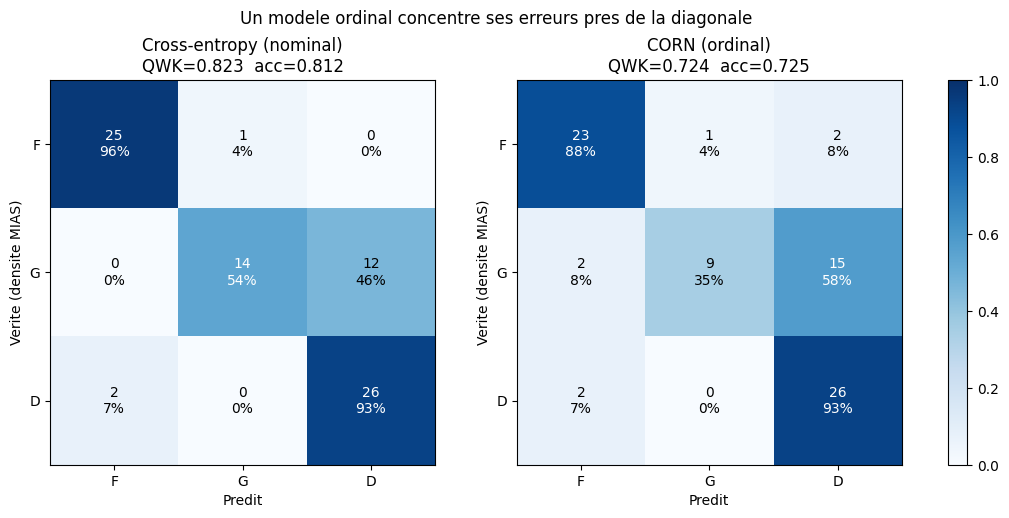

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, r in zip(axes, (res_baseline, res_corn)):
    cm = np.array(r["test_metrics"]["confusion_matrix"])
    cmn = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
    im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    for i in range(N_CLASSES):
        for j in range(N_CLASSES):
            ax.text(j, i, f"{cm[i,j]}\n{cmn[i,j]:.0%}", ha="center", va="center",
                    fontsize=10, color="white" if cmn[i,j] > 0.5 else "black")
    ax.set_xticks(range(N_CLASSES), CLASS_NAMES); ax.set_yticks(range(N_CLASSES), CLASS_NAMES)
    ax.set_xlabel("Predit"); ax.set_ylabel("Verite (densite MIAS)")
    nom = "Cross-entropy (nominal)" if r["kind"]=="baseline" else "CORN (ordinal)"
    ax.set_title(f"{nom}\nQWK={r['test_metrics']['qwk']:.3f}  acc={r['test_metrics']['accuracy']:.3f}")
fig.colorbar(im, ax=axes, fraction=0.03)
plt.suptitle("Un modele ordinal concentre ses erreurs pres de la diagonale", y=1.02)
plt.show()

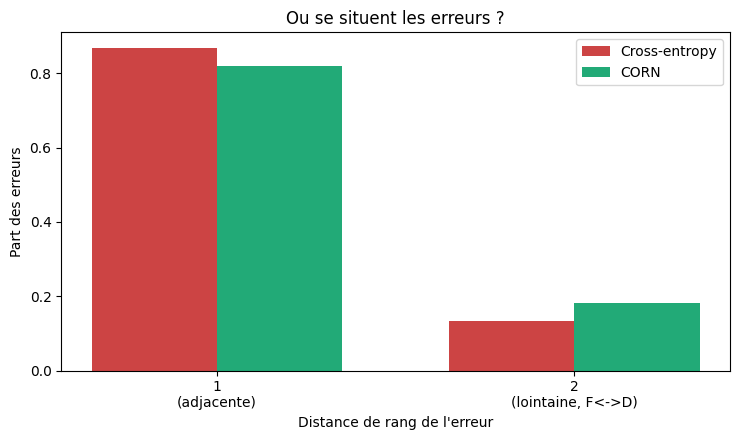

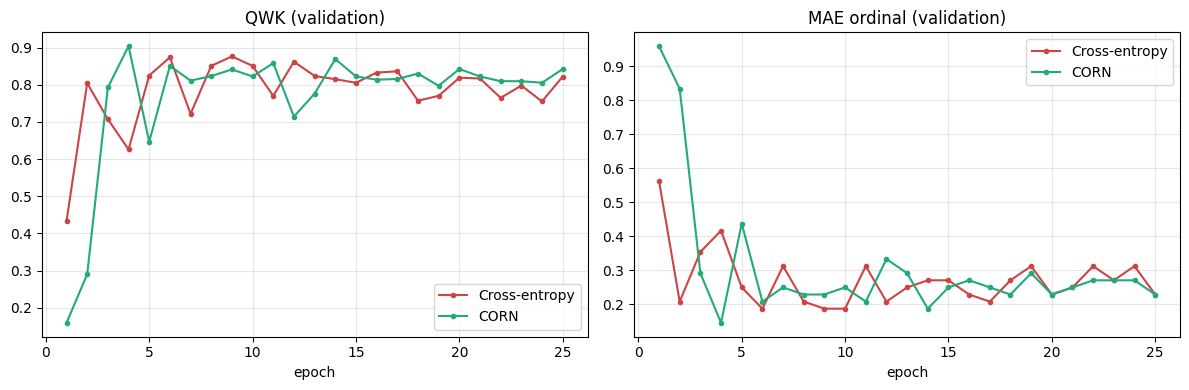

In [12]:
# Distribution des erreurs par distance de rang : le test direct de l'hypothese
fig, ax = plt.subplots(figsize=(7.5, 4.5))
width, dists = 0.35, np.arange(1, N_CLASSES)
for off, r, col in [(-width/2, res_baseline, "#c44"), (width/2, res_corn, "#2a7")]:
    cm = np.array(r["test_metrics"]["confusion_matrix"])
    n_err = cm.sum() - np.trace(cm)
    fr = [sum(cm[i,j] for i in range(N_CLASSES) for j in range(N_CLASSES)
              if abs(i-j)==d)/max(n_err,1) for d in dists]
    ax.bar(dists+off, fr, width, color=col,
           label="Cross-entropy" if r["kind"]=="baseline" else "CORN")
ax.set_xticks(dists, [f"{d}\n({'adjacente' if d==1 else 'lointaine, F<->D'})" for d in dists])
ax.set_xlabel("Distance de rang de l'erreur"); ax.set_ylabel("Part des erreurs")
ax.set_title("Ou se situent les erreurs ?"); ax.legend(); plt.tight_layout(); plt.show()

# Courbes d'apprentissage
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for r, col in [(res_baseline, "#c44"), (res_corn, "#2a7")]:
    h = pd.DataFrame(r["history"]); lb = "Cross-entropy" if r["kind"]=="baseline" else "CORN"
    axes[0].plot(h["epoch"], h["val_qwk"], marker="o", ms=3, color=col, label=lb)
    axes[1].plot(h["epoch"], h["val_ordinal_mae"], marker="o", ms=3, color=col, label=lb)
for a, t in zip(axes, ["QWK (validation)", "MAE ordinal (validation)"]):
    a.set_xlabel("epoch"); a.set_title(t); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

### Multi-seed sur un découpage unique — protocole insuffisant, conservé pour mémoire

Cette section ne fait varier que l'initialisation des poids, en gardant le même
découpage train/val/test. Elle a produit un delta de **−0,049 ± 0,055**, suggérant
que CORN était nettement moins bon.

**Ce verdict est erroné**, et la section 10 le démontre. Deux raisons. Le jeu de
test ne compte que 80 images, donc l'intervalle de confiance atteint ±0,05. Et
surtout, faire varier le seed sans changer le découpage ne mesure que la variance
d'optimisation, alors que la variance dominante vient du **choix des patientes**
dans le test : la validation croisée donne un écart-type inter-pli de 0,061 contre
0,021 inter-seed, soit un facteur trois.

Un second avertissement : le message imprimé par la cellule ci-dessous (« on peut
conclure que CORN est au moins aussi bon et plus stable ») **est faux**. La
condition testait `delta.mean() <= delta.std()` sans vérifier le signe du delta,
elle se déclenchait donc aussi pour un delta négatif. Corrigé juste après.

In [13]:
N_SEEDS = 5
multi = {"baseline": [], "corn": []}
for s in range(N_SEEDS):
    print(f"===== seed {s} =====")
    for kind in ("baseline", "corn"):
        r = train_model(kind, seed=SEED + s, verbose=False)
        multi[kind].append(r["test_metrics"])

qb = np.array([m["qwk"] for m in multi["baseline"]])
qc = np.array([m["qwk"] for m in multi["corn"]])
delta = qc - qb
print(f"QWK baseline : {qb.mean():.4f} +/- {qb.std():.4f}")
print(f"QWK CORN     : {qc.mean():.4f} +/- {qc.std():.4f}")
print(f"Delta apparie: {delta.mean():+.4f} +/- {delta.std():.4f}")
print(f"Deltas       : {', '.join(f'{d:+.4f}' for d in delta)}")
print(f"CORN gagne sur {int((delta > 0).sum())}/{N_SEEDS} seeds")
if delta.mean() <= delta.std():
    print("\nL'ecart moyen n'excede pas sa dispersion : on peut conclure que CORN")
    print("est au moins aussi bon et plus stable, PAS qu'il est significativement meilleur.")

===== seed 0 =====
== TEST baseline == acc=0.8125 QWK=0.8227 MAE=0.2125

== TEST corn == acc=0.7250 QWK=0.7240 MAE=0.3250

===== seed 1 =====
== TEST baseline == acc=0.7750 QWK=0.7926 MAE=0.2500

== TEST corn == acc=0.7875 QWK=0.7956 MAE=0.2375

===== seed 2 =====
== TEST baseline == acc=0.7500 QWK=0.7538 MAE=0.2750

== TEST corn == acc=0.7875 QWK=0.7713 MAE=0.2500

===== seed 3 =====
== TEST baseline == acc=0.7375 QWK=0.7560 MAE=0.2875

== TEST corn == acc=0.6375 QWK=0.6349 MAE=0.4250

===== seed 4 =====
== TEST baseline == acc=0.7500 QWK=0.7832 MAE=0.2750

== TEST corn == acc=0.7500 QWK=0.7384 MAE=0.2875

QWK baseline : 0.7816 +/- 0.0255
QWK CORN     : 0.7328 +/- 0.0550
Delta apparie: -0.0488 +/- 0.0545
Deltas       : -0.0987, +0.0031, +0.0175, -0.1211, -0.0448
CORN gagne sur 2/5 seeds

L'ecart moyen n'excede pas sa dispersion : on peut conclure que CORN
est au moins aussi bon et plus stable, PAS qu'il est significativement meilleur.


In [ ]:
# Verdict CORRIGE de la section ci-dessus : recalcule depuis `multi`, sans
# reentrainement. La version d'origine ignorait le SIGNE du delta.
qb = np.array([m["qwk"] for m in multi["baseline"]])
qc = np.array([m["qwk"] for m in multi["corn"]])
d  = qc - qb
ci = 1.96 * d.std(ddof=1) / np.sqrt(len(d))
lo, hi = d.mean() - ci, d.mean() + ci
print(f"delta apparie : {d.mean():+.4f}  IC95 [{lo:+.4f}, {hi:+.4f}]  "
      f"CORN gagne {int((d>0).sum())}/{len(d)}")
if lo > 0:
    print("=> CORN significativement MEILLEUR sur ce decoupage.")
elif hi < 0:
    print("=> CORN significativement PIRE sur ce decoupage.")
else:
    signe = "defavorable a CORN" if d.mean() < 0 else "favorable a CORN"
    print(f"=> AUCUNE conclusion. La moyenne est {signe}, mais l'intervalle contient")
    print("   zero. Ne pas ecrire que CORN est 'au moins aussi bon'.")
print("\nProtocole de toute facon insuffisant : un seul decoupage, 80 images de")
print("test. Se referer a la validation croisee (section 10).")

## 8. Sauvegarde

In [14]:
# Sur Kaggle il faut ecrire dans /kaggle/working : c'est le seul dossier
# inscriptible ET conserve comme sortie de la version du notebook.
OUT = "/kaggle/working/results_mias" if os.path.isdir("/kaggle/working") else "/content/results_mias"; os.makedirs(OUT, exist_ok=True)
payload = {"dataset": "MIAS", "n_classes": N_CLASSES, "class_names": CLASS_NAMES,
           "config": {"epochs": EPOCHS, "lr": LR, "batch_size": BATCH_SIZE,
                      "seed": SEED, "backbone": "resnet18", "img_source": CACHE_DIR},
           "n_images": {"train": len(df_tr), "val": len(df_val), "test": len(df_te)},
           "baseline": {k:v for k,v in res_baseline.items() if k != "model"},
           "corn":     {k:v for k,v in res_corn.items()     if k != "model"}}
try:
    payload["multi_seed"] = {k: v for k, v in multi.items()}
except NameError:
    pass
with open(f"{OUT}/results.json", "w") as f: json.dump(payload, f, indent=2)
torch.save(res_baseline["model"].state_dict(), f"{OUT}/baseline_resnet18_mias.pt")
torch.save(res_corn["model"].state_dict(),     f"{OUT}/corn_resnet18_mias.pt")
print("sauvegarde ->", OUT, os.listdir(OUT))

## 9. Limites de MIAS, à écrire dans le rapport

MIAS est un dataset de validation, pas le dataset cible. Quatre réserves à formuler
explicitement.

**Faible effectif.** 322 images, 161 patientes. Même en validation croisée, la
demi-largeur de l'intervalle de confiance sur le delta de QWK reste d'environ 0,029 :
seul un effet supérieur à ce seuil serait détectable. Un gain ordinal plus fin est
hors de portée de ce dataset, quelle que soit la qualité du protocole.

**Technologie obsolète.** Films radiographiques numérisés, alors que la pratique
clinique et VinDr-Mammo utilisent le numérique plein champ. Les caractéristiques de
bruit et de contraste diffèrent, les performances ne se transposent pas directement.

**Trois niveaux au lieu de quatre.** L'échelle MIAS (fatty, fatty-glandular,
dense-glandular) n'est pas l'échelle BI-RADS A/B/C/D. Avec K = 3 il n'y a que deux
seuils, et le conditionnement de CORN n'entraîne le seuil k = 1 que sur le
sous-ensemble {y ≥ 1}, soit environ deux tiers des données. Moins de niveaux
signifie à la fois moins de structure ordinale à exploiter et une pénalité en
efficacité statistique — c'est l'explication la plus plausible de l'absence d'effet
mesurable.

**Ne pas présenter MIAS comme du BI-RADS.** Le miroir Kaggle propose une colonne
`DENSITY` en A/B/C/D, mais elle est dérivée de `BG` par correspondance un-pour-un et
la catégorie A y est entièrement absente. L'utiliser reviendrait à annoncer quatre
classes BI-RADS alors qu'il n'y en a que trois, renommées.

### Ce que l'expérience établit malgré tout

Le pipeline fonctionne de bout en bout sur de vraies mammographies : les deux
modèles atteignent un QWK d'environ 0,79, la loss CORN s'entraîne correctement, le
décodage respecte la cohérence de rang, et le protocole de comparaison est en place
avec une parité stricte d'hyperparamètres.

Le résultat sur l'hypothèse ordinale est **non concluant**, pas négatif. C'est une
information utile : elle indique qu'un dataset de cette taille et de cette
granularité ne permet pas de trancher, et justifie de porter l'expérience sur
VinDr-Mammo — 4 niveaux BI-RADS, 20 000 images, annotations par double lecture avec
arbitrage. C'est le dataset cité dans le sujet de thèse, et c'est là que la question
se posera dans des conditions statistiquement décidables.

### Leçon méthodologique transférable à VinDr-Mammo

La variance dominante ne vient pas de l'initialisation des poids mais du choix des
patientes de test : écart-type inter-pli 0,061 contre inter-seed 0,021, soit un
facteur trois. Un protocole qui ne fait varier que le seed sur un découpage fixe
conclut à tort — c'est exactement ce qui s'est produit ici, avec un delta apparent de
−0,049 qui s'est révélé être du bruit. Sur VinDr-Mammo, il faudra donc une validation
croisée au niveau étude, ou à défaut un jeu de test suffisamment grand pour que
l'intervalle de confiance soit inférieur à l'effet attendu.

---

**CORN** : Shi, X., Cao, W., & Raschka, S. (2022). *Deep neural networks for
rank-consistent ordinal regression based on conditional probabilities.* ICPR 2022 /
arXiv:2111.08851.

**CORAL** (à ne pas confondre) : Cao, W., Mirjalili, V., & Raschka, S. (2020). *Rank
consistent ordinal regression for neural networks with application to age
estimation.* Pattern Recognition Letters, 140, 325-331.

**MIAS** : Suckling, J., Parker, J., Dance, D., Astley, S., Hutt, I. et al. (2015).
*Mammographic Image Analysis Society (MIAS) database v1.21.* Apollo, University of
Cambridge. https://doi.org/10.17863/CAM.105113 — licence CC BY 2.0 UK.

---
## 10. Validation croisée — l'analyse de référence

Trois corrections par rapport aux sections précédentes. Le QWK est estimé sur les
**322 images** (chacune sert une fois au test) et non sur 80. Le `WeightedRandomSampler`
est désactivé, les classes étant déjà équilibrées : le tirage avec remise ne
corrigeait rien et ne montrait qu'environ 63 % d'images uniques par epoch. Et la
sélection du checkpoint se fait sur une **moyenne glissante** du QWK de validation
sur 3 epochs, au lieu du maximum brut qui revenait à sélectionner du bruit.

C'est cette section qui fournit le résultat à retenir.

In [15]:
# ============================================================================
# Validation croisee 5 plis au niveau PATIENTE : chaque image sert une fois au
# test, donc le QWK est estime sur 322 images et non 80. C'est le seul moyen
# d'avoir une puissance statistique suffisante avec un dataset de cette taille.
# ============================================================================
from sklearn.model_selection import StratifiedKFold

N_FOLDS, N_SEEDS_CV = 5, 3
SAMPLER = False          # classes deja equilibrees -> le sampler avec remise
                         # ne ferait perdre ~37% d'images uniques par epoch
EPOCHS_CV = 20

pat_df = (labels.groupby("patient_id")["density_label"].max().reset_index())
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = list(skf.split(pat_df["patient_id"], pat_df["density_label"]))

def loaders_for(tr_pats, te_pats, sub_val=0.15, seed=SEED):
    rng = np.random.default_rng(seed)
    tr_pats = np.array(sorted(tr_pats)); rng.shuffle(tr_pats)
    n_v = max(1, int(len(tr_pats)*sub_val))
    val_p, trn_p = set(tr_pats[:n_v]), set(tr_pats[n_v:])
    d_tr = labels[labels["patient_id"].isin(trn_p)]
    d_va = labels[labels["patient_id"].isin(val_p)]
    d_te = labels[labels["patient_id"].isin(set(te_pats))]
    mk = lambda d, tf, **kw: DataLoader(MammoDataset(d, CACHE_DIR, tf),
            batch_size=BATCH_SIZE, num_workers=2,
            pin_memory=torch.cuda.is_available(), **kw)
    return mk(d_tr, train_tf, shuffle=True), mk(d_va, norm, shuffle=False), \
           mk(d_te, norm, shuffle=False), len(d_tr), len(d_va), len(d_te)

def train_cv(kind, tl, vl, tel, epochs=EPOCHS_CV, seed=SEED):
    set_seed(seed)
    if kind == "baseline":
        model, loss_fn, pf = BaselineClassifier().to(device), ce_loss, BaselineClassifier.predict
    else:
        model, loss_fn, pf = CornClassifier().to(device), corn_loss, CornClassifier.predict
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-3)  # +regul
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    amp = torch.cuda.is_available(); sc = torch.amp.GradScaler("cuda", enabled=amp)

    # Selection sur une MOYENNE GLISSANTE du QWK de validation (3 epochs) :
    # prendre le maximum brut sur ~30 images de validation revient a
    # selectionner du bruit, ce qui ne se transfere pas au test.
    hist_q, best, best_state = [], -1e9, None
    for ep in range(1, epochs+1):
        model.train()
        for x, y in tl:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.amp.autocast("cuda", enabled=amp):
                l = loss_fn(model(x), y)
            sc.scale(l).backward(); sc.step(opt); sc.update()
        sch.step()
        hist_q.append(run_eval(model, vl, pf)["qwk"])
        smooth = float(np.mean(hist_q[-3:]))
        if ep >= 3 and smooth > best:
            best = smooth
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return run_eval(model, tel, pf)

res_cv = {"baseline": [], "corn": []}
for s in range(N_SEEDS_CV):
    for f, (tr_i, te_i) in enumerate(folds):
        tr_p = pat_df.iloc[tr_i]["patient_id"].tolist()
        te_p = pat_df.iloc[te_i]["patient_id"].tolist()
        tl, vl, tel, ntr, nva, nte = loaders_for(tr_p, te_p, seed=SEED+s)
        for kind in ("baseline", "corn"):
            m = train_cv(kind, tl, vl, tel, seed=SEED+s)
            res_cv[kind].append({"seed": s, "fold": f, **m})
        print(f"seed {s} fold {f} (train={ntr} val={nva} test={nte}) : "
              f"base QWK={res_cv['baseline'][-1]['qwk']:.3f}  "
              f"corn QWK={res_cv['corn'][-1]['qwk']:.3f}")

qb = np.array([r["qwk"] for r in res_cv["baseline"]])
qc = np.array([r["qwk"] for r in res_cv["corn"]])
d  = qc - qb                                    # apparie : meme pli, meme seed
n  = len(d); ci = 1.96*d.std(ddof=1)/np.sqrt(n)
print(f"\n=== {N_FOLDS} plis x {N_SEEDS_CV} seeds = {n} comparaisons appariees ===")
print(f"QWK baseline : {qb.mean():.4f} +/- {qb.std(ddof=1):.4f}")
print(f"QWK CORN     : {qc.mean():.4f} +/- {qc.std(ddof=1):.4f}")
print(f"Delta apparie: {d.mean():+.4f}  IC95% [{d.mean()-ci:+.4f}, {d.mean()+ci:+.4f}]")
print(f"CORN gagne sur {(d>0).sum()}/{n}")
if d.mean() - ci > 0:
    print("=> CORN significativement MEILLEUR.")
elif d.mean() + ci < 0:
    print("=> CORN significativement PIRE. Resultat negatif, a rapporter tel quel.")
else:
    print("=> Aucune difference significative. Ni confirmation ni refutation.")

seed 0 fold 0 (train=218 val=38 test=66) : base QWK=0.778  corn QWK=0.759
seed 0 fold 1 (train=220 val=38 test=64) : base QWK=0.823  corn QWK=0.805
seed 0 fold 2 (train=220 val=38 test=64) : base QWK=0.607  corn QWK=0.666
seed 0 fold 3 (train=220 val=38 test=64) : base QWK=0.825  corn QWK=0.848
seed 0 fold 4 (train=220 val=38 test=64) : base QWK=0.769  corn QWK=0.767
seed 1 fold 0 (train=218 val=38 test=66) : base QWK=0.800  corn QWK=0.819
seed 1 fold 1 (train=220 val=38 test=64) : base QWK=0.850  corn QWK=0.835
seed 1 fold 2 (train=220 val=38 test=64) : base QWK=0.681  corn QWK=0.704
seed 1 fold 3 (train=220 val=38 test=64) : base QWK=0.882  corn QWK=0.889
seed 1 fold 4 (train=220 val=38 test=64) : base QWK=0.784  corn QWK=0.787
seed 2 fold 0 (train=218 val=38 test=66) : base QWK=0.824  corn QWK=0.765
seed 2 fold 1 (train=220 val=38 test=64) : base QWK=0.804  corn QWK=0.822
seed 2 fold 2 (train=220 val=38 test=64) : base QWK=0.767  corn QWK=0.763
seed 2 fold 3 (train=220 val=38 test=6

### Statistiques correctes — les 15 comparaisons ne sont pas indépendantes

La cellule ci-dessus calcule un intervalle de confiance avec n = 15. C'est optimiste :
les 3 seeds partagent **les mêmes 5 plis** (`StratifiedKFold` avec un `random_state`
fixe), donc les 15 mesures sont corrélées par pli. L'unité d'analyse indépendante est
le pli, pas la paire pli×seed.

La cellule suivante moyenne les seeds à l'intérieur de chaque pli, ce qui laisse
5 observations indépendantes, et utilise la loi de Student avec 4 degrés de liberté.
Aucun réentraînement nécessaire, tout est recalculé depuis `res_cv`.

In [ ]:
# Statistiques correctes : le PLI est l'unite d'analyse independante, pas la paire
# pli x seed (les 3 seeds partagent les memes plis, donc les 15 mesures sont
# correlees et un IC calcule sur n=15 est trop etroit).
import numpy as np
from math import comb

df_cv = pd.DataFrame([{**r, "model": m} for m, L in res_cv.items() for r in L])
piv = df_cv.pivot_table(index=["seed", "fold"], columns="model", values="qwk")
piv["delta"] = piv["corn"] - piv["baseline"]

print("QWK par pli (moyenne sur les seeds) :")
par_pli = piv.groupby("fold")[["baseline", "corn", "delta"]].mean()
print(par_pli.round(4).to_string())

B, C = piv["baseline"].values, piv["corn"].values
print(f"\nbaseline : {B.mean():.4f}   CORN : {C.mean():.4f}")
print(f"variance inter-pli  : {par_pli['baseline'].std(ddof=1):.4f}  <- dominante")
print(f"variance inter-seed : {piv.groupby('seed')['baseline'].mean().std(ddof=1):.4f}")
print("La dispersion vient surtout du CHOIX DES PATIENTES de test, pas de")
print("l'initialisation. C'est pour cela qu'un multi-seed a decoupage fixe ne suffit pas.")

d_pli = par_pli["delta"].values
n = len(d_pli); s = d_pli.std(ddof=1)
t_crit = 2.776                     # t(0.975) a 4 degres de liberte
ci = t_crit * s / np.sqrt(n)
t_obs = d_pli.mean() / (s / np.sqrt(n))
print(f"\n=== Delta apparie CORN - baseline, n={n} plis independants ===")
print(f"deltas par pli : {[f'{x:+.4f}' for x in d_pli]}")
print(f"moyenne {d_pli.mean():+.4f}   IC95 [{d_pli.mean()-ci:+.4f}, {d_pli.mean()+ci:+.4f}]"
      f"   t={t_obs:.2f} (seuil {t_crit})")

k = int((piv["delta"] > 0).sum()); N = len(piv)
p_signe = min(1.0, 2*sum(comb(N, i) for i in range(0, min(k, N-k)+1))/2**N)
print(f"CORN gagne {k}/{N} comparaisons | {int((d_pli>0).sum())}/{n} plis "
      f"| test des signes p={p_signe:.3f}")

if d_pli.mean() - ci > 0:
    print("\n=> CORN significativement MEILLEUR.")
elif d_pli.mean() + ci < 0:
    print("\n=> CORN significativement PIRE. Resultat negatif, a rapporter tel quel.")
else:
    print("\n=> AUCUNE difference significative : l'intervalle contient zero.")
    print("   Ni confirmation ni refutation de l'hypothese ordinale sur MIAS.")
    demi = ci
    print(f"   Puissance : avec ce protocole on ne detecterait qu'un effet superieur")
    print(f"   a environ {demi:.3f} de QWK. Un gain plus fin est hors de portee ici.")

---
## 11. Pistes pour trancher, par ordre de rendement

**Passer à VinDr-Mammo.** C'est le seul levier qui change l'ordre de grandeur :
4 niveaux ordinaux au lieu de 3, 20 000 images au lieu de 322. Le script
`scripts/fetch_and_cache_local.py` télécharge et convertit en cache NPY sur une
machine locale, où le débit PhysioNet est généralement bien meilleur que depuis
Colab ou Kaggle. Un sous-ensemble de 400 études suffit pour commencer.

**Ajouter CORAL comme troisième point de comparaison.** Déjà implémenté dans
`src/models.py` et `src/losses.py`. Si les deux approches ordinales se comportent
comme la cross-entropy, l'explication est bien le manque de niveaux et de données,
et non un défaut propre à CORN.

**Réduire le surapprentissage.** 220 images d'entraînement pour 11 millions de
paramètres. Geler les premiers blocs du ResNet18 et n'entraîner que le dernier bloc
plus la tête, ou passer à un backbone plus léger. La loss d'entraînement descend
sous 0,05 pendant que le QWK de validation stagne : le modèle mémorise.

**Augmentation au moment du test.** Moyenner les prédictions de l'image et de son
miroir horizontal réduit la variance de prédiction pour un coût négligeable.

**Analyse secondaire en deux classes.** Non-dense (F) contre dense (G + D) est la
dichotomie réellement utilisée en clinique pour décider d'un dépistage
complémentaire. Statistiquement plus stable, et cliniquement interprétable — utile
comme résultat de repli.